In [4]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.util as cutil
import numpy as np
from tqdm import tqdm
import matplotlib.gridspec as gridspec  # To control widths
from scipy.integrate import trapezoid
import falwa.utilities as utilities
from falwa.oopinterface import QGFieldNH18
from math import pi
import cftime

### Necessary functions

In [5]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [6]:
from scipy.signal import butter, filtfilt

import xarray as xr
import numpy as np

import xarray as xr

import xarray as xr

def rolling_periodic(
    da: xr.DataArray,
    dim: str,
    window: int,
    center: bool = True
) -> xr.DataArray:

    n = window // 2 if center else window - 1

    # Extend array by wrapping values from both ends along chosen dimension
    da_extended = xr.concat([da.isel({dim: slice(-n, None)}),
                             da,
                             da.isel({dim: slice(0, n)})],
                            dim=dim)

    # Apply rolling mean
    rolled = da_extended.rolling({dim: window}, center=center).mean()

    # Trim back to original length
    result = rolled.isel({dim: slice(n, -n)})
    result[dim] = da[dim]  # restore original coords

    return result

def lowpass_fourier(da, period_days=4 , dt=1, time_dim='time'):
    
    n_time = da.sizes[time_dim]

    # FFT frequencies (cycles per day)
    freqs = np.fft.fftfreq(n_time, d=dt)
    cutoff = 1 / period_days  # max frequency to keep

    # FFT along time axis
    fft_vals = np.fft.fft(da, axis=0)

    # Low-pass mask
    mask = np.abs(freqs) <= cutoff
    fft_vals_filtered = fft_vals * mask[:, np.newaxis, np.newaxis]

    # Inverse FFT
    filtered_data = np.fft.ifft(fft_vals_filtered, axis=0).real

    return xr.DataArray(filtered_data, dims=da.dims, coords=da.coords, name=da.name)

def longitude_running_avg(da, lon_window_deg=15, lon_dim='lon'):
    # Compute number of points corresponding to lon_window_deg
    lon_vals = da[lon_dim].values
    if len(lon_vals) > 1:
        lon_res = np.mean(np.diff(lon_vals))
        window_points = max(1, int(np.round(lon_window_deg / lon_res)))
    else:
        window_points = 1

    print('longitudinal filter window: '+ str(window_points))

    # Apply rolling mean along longitude
    da_smoothed = rolling_periodic(da, lon_dim , window = window_points, center=True)
    return da_smoothed

def deseasonalize_daily(da):
    daily_clim = da.groupby("time.dayofyear").mean("time")
    anomalies = da.groupby("time.dayofyear") - daily_clim    
    return anomalies

def deseasonalize_roll(da):
    running_mean = rolling_periodic(da=da,dim='time',window=30,center=True)
    anomalies = da - running_mean  
    return anomalies

In [7]:
def compute_covariance_xr(A,B):
    
    #A = A.where(np.isfinite(A), 0)
    #B = B.where(np.isfinite(B), 0)
    #A = A.where(np.isnan(A), 0)
    #B = B.where(np.isnan(B), 0)
    
    # Compute means lazily (Dask-aware)
    A_mean = A.mean(dim='time')
    B_mean = B.mean(dim='time')
    
    # Compute anomalies lazily
    A_anom = A - A_mean
    B_anom = B - B_mean
    
    # Covariance calculation
    cov = (A_anom * B_anom).mean(dim='time')
    return cov

def covariance_bootstrap(A,B,n_iterations,n_sample):
    length = len(A)
    cov_set = []
    for n in tqdm(range(n_iterations)):
        idxs = np.random.choice(np.arange(0,length,1),size=n_sample,replace=False)
        cov_set.append(compute_covariance_xr(A[idxs],B[idxs]))
    cov_set_da = xr.concat(cov_set,dim = 'realization')
    return cov_set_da.std('realization')*(np.sqrt(n_sample)/np.sqrt(len(A)))        

### Importing data

In [8]:
#here we focus on the asymmetric baseline simulation
%cd /emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/falwa_output_nosfc/

/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/falwa_output_nosfc


In [10]:
#apply filters (if not done previously)
apply = True
if apply:
    months_range = range(13, 70) #select months range
    files_falwa = [f"falwa_output_1.5x1.5_{str(i).zfill(4)}.nc" for i in months_range]
    files_uvt = [f"atm_daily_uvt__{str(i).zfill(4)}.nc" for i in months_range]
    ds_fluxs = xr.open_mfdataset(files_falwa, combine="by_coords",parallel=True)
    ds_fluxs = flip_and_append(ds_fluxs)
    lwa = ds_fluxs['dw_lwa']
    ucomp = ds_fluxs['u_baro'] - ds_fluxs['dw_uref']
    F1 = ds_fluxs['adv_flux_f1']
    F2 = ds_fluxs['adv_flux_f2']
    F3 = ds_fluxs['adv_flux_f3']
    lwa = longitude_running_avg(lowpass_fourier(lwa))
    ucomp = longitude_running_avg(lowpass_fourier(ucomp))
    F1 = longitude_running_avg(lowpass_fourier(F1))
    F2 = longitude_running_avg(lowpass_fourier(F2))
    F3 = longitude_running_avg(lowpass_fourier(F3))
    ds_filtered = lwa.to_dataset()
    ds_filtered['F1'] = F1
    ds_filtered['F2'] = F2
    ds_filtered['F3'] = F3
    ds_filtered['dw_uref'] = ds_fluxs['dw_uref']
    ds_filtered['ucomp'] = ucomp
    ds_filtered.to_netcdf('../tot/filtered_decomposition_data_flipped_2-51_nosfc.nc')
    ds_filtered.close()

<frozen importlib._bootstrap>:488: RuntimeWarning: numpy.ndarray size changed, may indicate binary incompatibility. Expected 16 from C header, got 96 from PyObject


longitudinal filter window: 10
longitudinal filter window: 10
longitudinal filter window: 10
longitudinal filter window: 10


/home/links/mf671/miniconda3/envs/prog_env/lib/python3.13/site-packages/numpy/fft/_pocketfft.py:94: RuntimeWarning: invalid value encountered in fft
  return ufunc(a, fct, axes=[(axis,), (), (axis,)], out=out)


longitudinal filter window: 10


In [11]:
#import dataset with decomposition data (output of previous cell)
ds = xr.open_dataset('../tot/filtered_decomposition_data_flipped_2-51_nosfc.nc')
lwa = ds['dw_lwa']
ucomp = ds['ucomp']
zonal_flux = ds['F1'] + ds['F3']
tot_zonal_flux = ds['F1'] + ds['F2'] + ds['F3']
lon = ds['lon']
lat = ds['lat']
cosphi = np.cos(np.deg2rad(lat)).broadcast_like(ucomp)

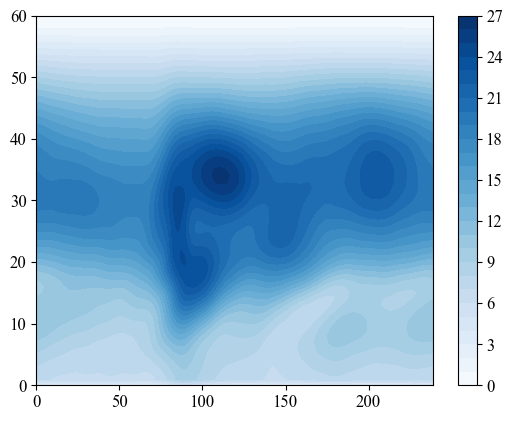

In [21]:
lwa_mean = lwa.mean(dim='time')
plt.contourf(lwa_mean,levels=np.arange(0,28,1),cmap='Blues')
plt.colorbar()